# Person 1 — Housing source, EDA and cleaning
The official Affordable Housing Production by Building dataset (`hg8x-zxpr`) is archived in `data/raw/df_housing_raw.csv`. The source retrieved on 2026-11-07 reproduces the supplied cleaned snapshot. Run from the repository root; this notebook works offline and verifies every supplied field before saving. Housing includes preservation and new construction and is dated by project start, rather than completion or occupancy. The following EDA figures describe this archived snapshot, not a promise that a future live refresh has the same values.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path("scripts").resolve()))
from cleaning import clean_housing, zip_text

housing_id = "hg8x-zxpr"
# Archived official source; see data/raw/manifest.json for retrieval and SHA-256.
# Do not silently refresh this file: a refresh changes all downstream results.
df_housing_raw = pd.read_csv("data/raw/df_housing_raw.csv", low_memory=False)
print("Archived raw shape:", df_housing_raw.shape)


Archived raw shape: (9551, 41)


In [3]:

df_housing_raw.head()


,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,street_name,borough,postcode,bbl,...,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,...,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,...,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


In [4]:

print("Number of rows:", df_housing_raw.shape[0])
print("Number of columns:", df_housing_raw.shape[1])


Number of rows: 9551
Number of columns: 41


In [5]:

print(df_housing_raw.columns.tolist())


['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '_1_br_units', '_2_br_units', '_3_br_units', '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']


In [6]:

df_housing_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   project_id                     9551 non-null   int64  
 1   project_name                   9551 non-null   object 
 2   project_start_date             9551 non-null   object 
 3   project_completion_date        7732 non-null   object 
 4   building_id                    7602 non-null   float64
 5   house_number                   9551 non-null   object 
 6   street_name                    9551 non-null   object 
 7   borough                        9551 non-null   object 
 8   postcode                       7593 non-null   float64
 9   bbl                            7530 non-null   float64
 10  bin                            7530 non-null   float64
 11  community_board                9551 non-null   object 
 12  council_district               9551 non-null   i

In [7]:

df_housing_raw.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
project_id,9551.0,NaN,NaN,NaN,67125.247409,8463.040347,44218.0,61418.5,68781.0,73850.5,82249.0
project_name,9551,3979,CONFIDENTIAL,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_start_date,9551,2346,2021-06-30T00:00:00.000,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_completion_date,7732,2066,2019-06-20T00:00:00.000,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_id,7602.0,NaN,NaN,NaN,582729.711655,401057.617968,375.0,117976.25,805625.5,980688.75,1022537.0
house_number,9551,3154,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street_name,9551,1567,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
borough,9551,5,Brooklyn,3649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
postcode,7593.0,NaN,NaN,NaN,10780.411432,504.437572,10001.0,10453.0,11102.0,11221.0,11694.0
bbl,7530.0,NaN,NaN,NaN,2510121977.677689,972093306.509762,1000050010.0,2026850033.0,3008497502.0,3039567554.5,5080477501.0


In [8]:

missing = df_housing_raw.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": (
        missing / len(df_housing_raw) * 100
    ).round(2)
})

missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)


,Missing Count,Missing Percentage
_6_br_units,9524,99.72
_5_br_units,9478,99.24
_4_br_units,8990,94.13
unknown_br_units,8862,92.79
other_income_units,8191,85.76
moderate_income_units,7857,82.26
extremely_low_income_units,7470,78.21
middle_income_units,6860,71.82
counted_homeownership_units,6821,71.42
studio_units,6353,66.52


In [9]:

print("Exact duplicate rows:",
      df_housing_raw.duplicated().sum())


Exact duplicate rows: 0


In [10]:

for col in ["borough", "postcode"]:
    print(f"\n{col}")
    print(df_housing_raw[col].value_counts(dropna=False))



borough
borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445
Name: count, dtype: int64

postcode
postcode
NaN        1958
11221.0     269
11233.0     232
11207.0     229
11212.0     212
           ... 
11417.0       1
11427.0       1
11422.0       1
10158.0       1
10069.0       1
Name: count, Length: 159, dtype: int64


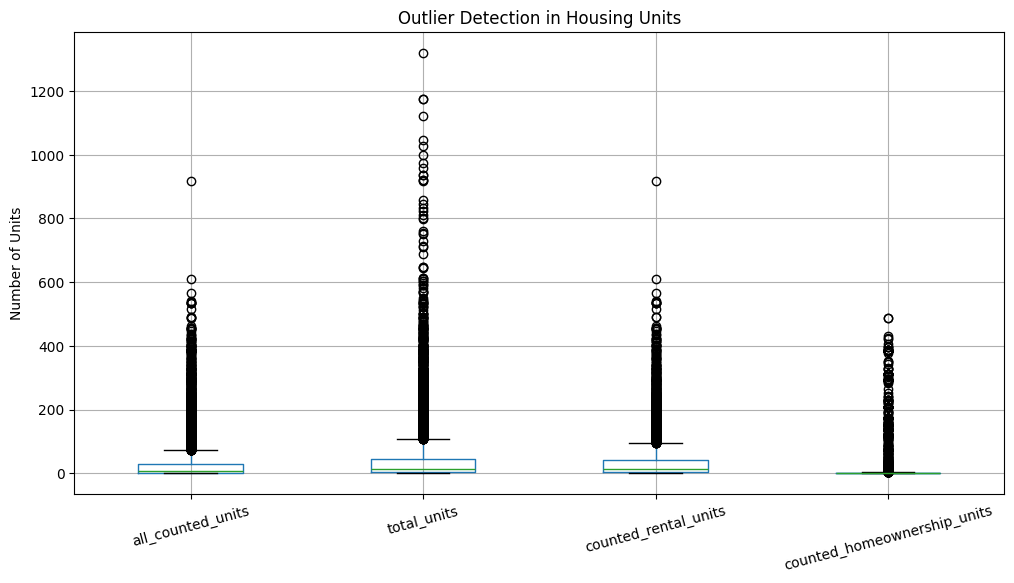

In [11]:

housing_columns = [
    "all_counted_units",
    "total_units",
    "counted_rental_units",
    "counted_homeownership_units"
]

plt.figure(figsize=(12, 6))

df_housing_raw[housing_columns].boxplot()

plt.title("Outlier Detection in Housing Units")
plt.ylabel("Number of Units")
plt.xticks(rotation=15)
plt.show()


In [12]:

for col in housing_columns:
    Q1 = df_housing_raw[col].quantile(0.25)
    Q3 = df_housing_raw[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_housing_raw[
        (df_housing_raw[col] < lower_bound) |
        (df_housing_raw[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} outliers")


all_counted_units: 1249 outliers
total_units: 1171 outliers
counted_rental_units: 743 outliers
counted_homeownership_units: 505 outliers


In [13]:

print("Unique projects:",
      df_housing_raw["project_id"].nunique())

print("Repeated project IDs:",
      df_housing_raw["project_id"].duplicated().sum())


Unique projects: 5928
Repeated project IDs: 3623


In [14]:

df_housing_clean = df_housing_raw.copy()

print("Original shape:", df_housing_raw.shape)
print("Clean dataset shape:", df_housing_clean.shape)


Original shape: (9551, 41)
Clean dataset shape: (9551, 41)


In [15]:

df_housing_clean.rename(
    columns={"postcode": "zip_code"},
    inplace=True
)

print(df_housing_clean.columns.tolist())


['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'house_number', 'street_name', 'borough', 'zip_code', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '_1_br_units', '_2_br_units', '_3_br_units', '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']


In [16]:
df_housing_clean["zip_code"] = zip_text(df_housing_clean["zip_code"])
print(df_housing_clean["zip_code"].dtype)
print(df_housing_clean["zip_code"].value_counts().head(10))


string
zip_code
11221    269
11233    232
11207    229
11212    212
11239    212
10456    202
10457    182
11216    178
11206    177
10453    176
Name: count, dtype: Int64


In [17]:

df_housing_clean["borough"] = (
    df_housing_clean["borough"]
    .str.strip()
    .str.title()
)

print(df_housing_clean["borough"].value_counts())


borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445
Name: count, dtype: int64


In [18]:

df_housing_clean["project_start_date"] = pd.to_datetime(
    df_housing_clean["project_start_date"],
    errors="coerce"
)

df_housing_clean["year"] = (
    df_housing_clean["project_start_date"].dt.year.astype("Int64")
)

print(df_housing_clean[
    ["project_start_date", "year"]
].head(10))

print("\nYear values:")
print(df_housing_clean["year"].value_counts().sort_index())


  project_start_date  year
0         2026-06-30  2026
1         2026-06-30  2026
2         2026-06-30  2026
3         2026-06-30  2026
4         2026-06-30  2026
5         2026-06-30  2026
6         2026-06-30  2026
7         2026-06-30  2026
8         2026-06-30  2026
9         2026-06-30  2026

Year values:
year
2014    734
2015    694
2016    722
2017    703
2018    691
2019    816
2020    608
2021    780
2022    670
2023    872
2024    868
2025    854
2026    539
Name: count, dtype: Int64


In [19]:

missing_after = pd.DataFrame({
    "Missing Count": df_housing_clean.isnull().sum(),
    "Missing Percentage": (
        df_housing_clean.isnull().sum() /
        len(df_housing_clean) * 100
    ).round(2)
})

missing_after[missing_after["Missing Count"] > 0]


,Missing Count,Missing Percentage
project_completion_date,1819,19.05
building_id,1949,20.41
zip_code,1958,20.50
bbl,2021,21.16
bin,2021,21.16
census_tract,1958,20.50
neighborhood_tabulation_area,1958,20.50
latitude,1958,20.50
longitude,1958,20.50
latitude_internal,2044,21.40


In [20]:

missing_units = df_housing_clean[
    df_housing_clean["all_counted_units"].isnull()
]

missing_units[[
    "project_id",
    "project_name",
    "zip_code",
    "borough",
    "total_units",
    "counted_rental_units",
    "counted_homeownership_units",
    "all_counted_units"
]].head(15)


,project_id,project_name,zip_code,borough,total_units,counted_rental_units,counted_homeownership_units,all_counted_units
185,77719,67 4TH AVENUE,11217,Brooklyn,10,NaN,NaN,NaN
1764,73943,261 & 315 GRAND CONCOURSE,10451,Bronx,283,NaN,NaN,NaN
2292,74316,325 BOND STREET,11231,Brooklyn,425,NaN,NaN,NaN
3932,70577,2916 WEST 16TH STREET,11224,Brooklyn,324,NaN,NaN,NaN
4668,68409,55-61 SUMMIT,11231,Brooklyn,1,NaN,NaN,NaN
4670,68409,55-61 SUMMIT,11231,Brooklyn,1,NaN,NaN,NaN
4671,68409,55-61 SUMMIT,11231,Brooklyn,1,NaN,NaN,NaN
4672,68409,55-61 SUMMIT,11231,Brooklyn,1,NaN,NaN,NaN
4721,67510,ROSE CASTLE,11205,Brooklyn,122,NaN,NaN,NaN
5198,68432,LINDEN PLAZA PRESERVATION LP.YR15.FY20,11208,Brooklyn,32,NaN,NaN,NaN


In [21]:

unit_columns = [
    "extremely_low_income_units",
    "very_low_income_units",
    "low_income_units",
    "moderate_income_units",
    "middle_income_units",
    "other_income_units",
    "studio_units",
    "_1_br_units",
    "_2_br_units",
    "_3_br_units",
    "_4_br_units",
    "_5_br_units",
    "_6_br_units",
    "unknown_br_units"
]

missing_units[unit_columns].notna().sum()


extremely_low_income_units    0
very_low_income_units         0
low_income_units              0
moderate_income_units         0
middle_income_units           0
other_income_units            0
studio_units                  0
_1_br_units                   0
_2_br_units                   0
_3_br_units                   0
_4_br_units                   0
_5_br_units                   0
_6_br_units                   0
unknown_br_units              0
dtype: int64

In [22]:

date_columns = [
    "project_start_date",
    "project_completion_date",
    "building_completion_date"
]

for col in date_columns:
    df_housing_clean[col] = pd.to_datetime(
        df_housing_clean[col],
        errors="coerce"
    )

print(df_housing_clean[date_columns].dtypes)

print(df_housing_clean[date_columns].isnull().sum())


project_start_date          datetime64[ns]
project_completion_date     datetime64[ns]
building_completion_date    datetime64[ns]
dtype: object
project_start_date             0
project_completion_date     1819
building_completion_date    1666
dtype: int64


In [23]:

numeric_columns = [
    "all_counted_units",
    "total_units",
    "counted_rental_units",
    "counted_homeownership_units",
    "extremely_low_income_units",
    "very_low_income_units",
    "low_income_units",
    "moderate_income_units",
    "middle_income_units",
    "other_income_units",
    "studio_units",
    "_1_br_units",
    "_2_br_units",
    "_3_br_units",
    "_4_br_units",
    "_5_br_units",
    "_6_br_units",
    "unknown_br_units"
]

for col in numeric_columns:
    negative_count = (df_housing_clean[col] < 0).sum()
    print(f"{col}: {negative_count} negative values")


all_counted_units: 0 negative values
total_units: 0 negative values
counted_rental_units: 0 negative values
counted_homeownership_units: 0 negative values
extremely_low_income_units: 0 negative values
very_low_income_units: 0 negative values
low_income_units: 0 negative values
moderate_income_units: 0 negative values
middle_income_units: 0 negative values
other_income_units: 0 negative values
studio_units: 0 negative values
_1_br_units: 0 negative values
_2_br_units: 0 negative values
_3_br_units: 0 negative values
_4_br_units: 0 negative values
_5_br_units: 0 negative values
_6_br_units: 0 negative values
unknown_br_units: 0 negative values


In [24]:

valid_zip = df_housing_clean["zip_code"].dropna().str.match(
    r"^\d{5}$"
)

print("Valid ZIP codes:", valid_zip.sum())
print("Invalid ZIP codes:", (~valid_zip).sum())
print("Missing ZIP codes:", df_housing_clean["zip_code"].isna().sum())


Valid ZIP codes: 7593
Invalid ZIP codes: 0
Missing ZIP codes: 1958


In [25]:

print("Dataset shape:", df_housing_clean.shape)

print("\nRequired columns:")
print(
    df_housing_clean[
        ["zip_code", "borough", "year"]
    ].dtypes
)

print("\nMissing shared columns:")
print(
    df_housing_clean[
        ["zip_code", "borough", "year"]
    ].isnull().sum()
)

print("\nExact duplicate rows:",
      df_housing_clean.duplicated().sum())

print("\nUnique boroughs:")
print(df_housing_clean["borough"].unique())


Dataset shape: (9551, 42)

Required columns:
zip_code    string[python]
borough             object
year                 Int64
dtype: object

Missing shared columns:
zip_code    1958
borough        0
year           0
dtype: int64



Exact duplicate rows:

 0

Unique boroughs:
['Queens' 'Brooklyn' 'Manhattan' 'Bronx' 'Staten Island']


In [26]:
# Verify this notebook's documented steps agree with the reusable transformation.
expected = clean_housing(df_housing_raw)
pd.testing.assert_frame_equal(df_housing_clean, expected, check_dtype=False)

# Confirm the archived raw data reproduces the supplied snapshot semantically.
supplied = pd.read_csv("df_housing_clean.csv", dtype={"zip_code": "string"}, low_memory=False)
for c in ["project_start_date", "project_completion_date", "building_completion_date"]:
    supplied[c] = pd.to_datetime(supplied[c], errors="coerce")
pd.testing.assert_frame_equal(df_housing_clean.reset_index(drop=True),
    supplied.reset_index(drop=True), check_dtype=False)
print("PASS: all supplied housing fields reproduced from the archived raw source.")
df_housing_clean.to_csv("df_housing_clean.csv", index=False)


PASS: all supplied housing fields reproduced from the archived raw source.


In [27]:

# Optional download only inside Google Colab; local execution already saved the CSV.
try:
    from google.colab import files
except ImportError:
    print("Saved locally: df_housing_clean.csv")
else:
    files.download("df_housing_clean.csv")


Saved locally: df_housing_clean.csv


### Exploratory Data Analysis (EDA) – Housing Dataset

**1. Dataset Overview**
- The original housing dataset contains 9,551 rows and 41 columns.
- It includes information about affordable housing projects, buildings, locations, and housing units.

**2. Missing Values**
- Several columns contain missing values, especially bedroom and income-category columns.
- The `zip_code` column has 1,958 missing values.
- The `all_counted_units` column has 29 missing values.
- Missing values were not replaced with zero when the actual values were unknown.

**3. Duplicate Records**
- No exact duplicate rows were found.
- Repeated `project_id` values were retained because one project may contain multiple building records.

**4. Borough Distribution**
- Brooklyn has the highest number of records (3,649).
- The Bronx has 2,630 records.
- Manhattan has 1,485 records.
- Queens has 1,342 records.
- Staten Island has 445 records.

**5. Outlier Analysis**
- Box plots and the IQR method identified potential outliers in housing-unit columns.
- These values were retained because they may represent large but valid housing buildings.

**6. Data Quality**
- No negative values were found in the checked housing-unit columns.
- All available ZIP codes follow the five-digit format.
- Borough names were standardized.
- Date columns were converted to datetime format.
- A `year` column was extracted from `project_start_date`.